# Ejercicio 2

## Contexto

Una explotación agrícola controla dos zonas de un invernadero de tomates. En una de ellas se han observado síntomas de estrés en las plantas. Se desconoce si el motivo puede estar relacionado con la temperatura, la humedad o el funcionamiento de la climatización. El responsable solicita una investigación basada en datos.

## Datos disponibles

Genera **24 mediciones por zona**, una cada hora, con **48 registros** en total.

| Campo | Condición |
|---|---|
| hora | 0 a 23, en cada zona |
| zona | A o B |
| temperatura_c | A: 19–27°C; B: 22–30°C |
| humedad_pct | 40–75% |
| luminosidad_lux | 300–900lux |
| consumo_w | 100 + temperatura_c * 12 + luminosidad_lux * 0.08 + variación |

La variación del consumo será un valor aleatorio entre 0 y 25W. Se considera que una medición necesita revisión cuando la temperatura es **superior a 28°C** o la humedad es **inferior a 45%**.

## Lo que tienes que hacer

1. ¿Las dos zonas presentan condiciones ambientales similares? ¿Cuál te preocupa más?
2. ¿En qué momentos hay condiciones fuera de los límites recomendados? ¿Son incidencias de temperatura, humedad o ambas?
3. ¿Qué información aportan los datos sobre la relación entre temperatura, luminosidad y consumo eléctrico?
4. ¿Qué dos o tres representaciones gráficas ayudarían a explicar los resultados al responsable? Justifica la elección.
5. ¿Puedes concluir que las condiciones medidas son la causa del estrés de las plantas? ¿Qué comprobarías después?

## Entrega

- actividad.py o actividad.ipynb
- invernadero.csv
- alertas_invernadero.json
- Gráficos en jpg
- Conclusiones breves en md o en el notebook

## 1. Generación de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla fija para repetir la simulación.
np.random.seed(42)
hora = np.tile(np.arange(24), 2)
zona = ['A'] * 24 + ['B'] * 24
temperatura = np.concatenate([np.random.uniform(19, 27, 24), np.random.uniform(22, 30, 24)])
humedad = np.random.uniform(40, 75, 48)
luz = np.random.uniform(300, 900, 48)
df = pd.DataFrame({'hora': hora, 'zona': zona, 'temperatura_c': temperatura,
                   'humedad_pct': humedad, 'luminosidad_lux': luz,
                   'consumo_w': 100 + temperatura * 12 + luz * 0.08 + np.random.uniform(0, 25, 48)})
df['alerta_temperatura'] = df['temperatura_c'] > 28
df['alerta_humedad'] = df['humedad_pct'] < 45

print(df.head())
print(df.shape)

   hora zona  temperatura_c  ...   consumo_w  alerta_temperatura  alerta_humedad
0     0    A      21.996321  ...  420.168040               False           False
1     1    A      26.605714  ...  464.712716               False           False
2     2    A      24.855952  ...  438.730645               False           False
3     3    A      23.789268  ...  427.216979               False           False
4     4    A      20.248149  ...  369.773359               False           False

[5 rows x 8 columns]
(48, 8)


## 2. Incidencias y exportación

In [ ]:
# Exportamos todos los datos y seleccionamos las incidencias.
df.to_csv('invernadero.csv', index=False)
incidencias = df[df['alerta_temperatura'] | df['alerta_humedad']]
incidencias.to_json('alertas_invernadero.json', orient='records', indent=4, force_ascii=False)
print(incidencias.to_string(index=False))
print('Total de incidencias:', len(incidencias))
print(pd.crosstab(df['alerta_temperatura'], df['alerta_humedad']))


 hora zona  temperatura_c  humedad_pct  luminosidad_lux  consumo_w  alerta_temperatura  alerta_humedad
    8    A      23.808920    43.097238       844.539884 456.892604               False            True
   10    A      19.164676    41.582955       546.229754 398.315753               False            True
   18    A      22.455560    44.932348       680.042254 439.708345               False            True
   20    A      23.894823    42.609273       782.203246 451.571382               False            True
    0    B      25.648560    40.193274       784.464093 471.559224               False            True
    1    B      28.281408    68.541150       837.654780 521.161598                True           False
    5    B      22.371603    42.591563       556.264673 418.622808               False            True
    7    B      23.364193    44.055417       816.438350 450.044545               False            True
    9    B      29.591084    61.815434       606.448382 513.277266       

## 3. Análisis exploratorio

In [ ]:
print(df.select_dtypes(include='number').corr().round(2))
print(df.groupby('zona').mean(numeric_only=True).round(2))
print(df.groupby('zona')[['alerta_temperatura', 'alerta_humedad']].sum())


                 hora  temperatura_c  humedad_pct  luminosidad_lux  consumo_w
hora             1.00          -0.12        -0.02             0.22       0.01
temperatura_c   -0.12           1.00        -0.03             0.17       0.92
humedad_pct     -0.02          -0.03         1.00            -0.15      -0.06
luminosidad_lux  0.22           0.17        -0.15             1.00       0.49
consumo_w        0.01           0.92        -0.06             0.49       1.00
      hora  temperatura_c  ...  alerta_temperatura  alerta_humedad
zona                       ...                                    
A     11.5          22.52  ...                0.00            0.17
B     11.5          25.67  ...                0.21            0.21

[2 rows x 7 columns]
      alerta_temperatura  alerta_humedad
zona                                    
A                      0               4
B                      5               5


## 4. Gráficas

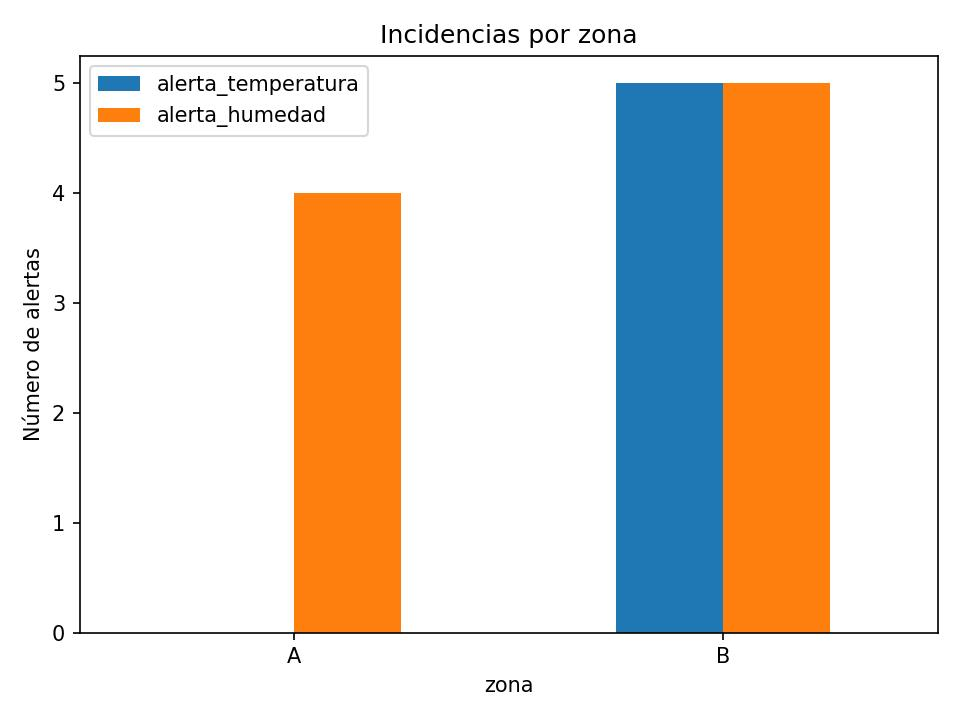

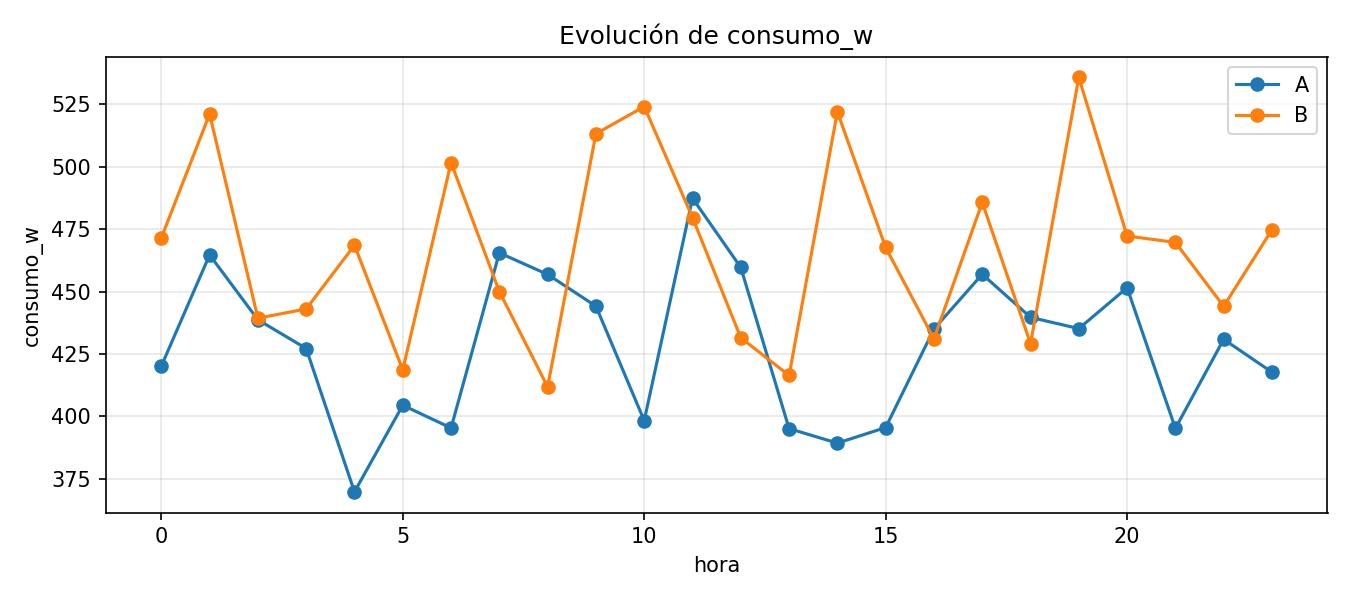

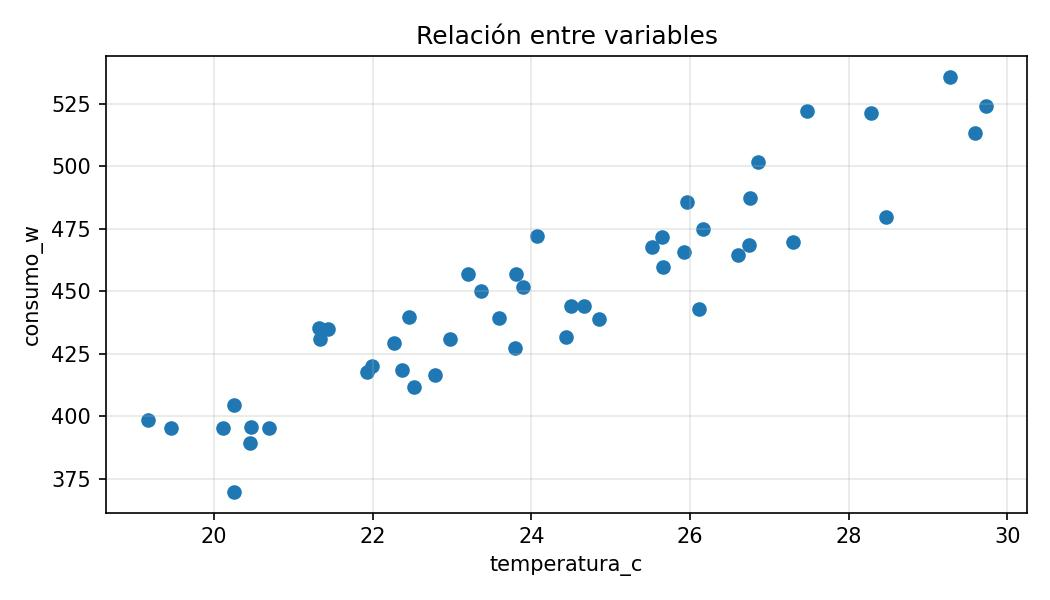

In [ ]:
# Evolución por registro: permite localizar los momentos problemáticos.
plt.figure(figsize=(9, 4))
for nombre, grupo in df.groupby('zona'):
    plt.plot(grupo['hora'], grupo['consumo_w'], marker='o', label=nombre)
plt.legend()
plt.xlabel('hora'); plt.ylabel('consumo_w'); plt.title('Evolución de consumo_w')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('evolucion.jpg', dpi=150); plt.show()
plt.figure(figsize=(7, 4))
plt.scatter(df['temperatura_c'], df['consumo_w'])
plt.xlabel('temperatura_c'); plt.ylabel('consumo_w'); plt.title('Relación entre variables')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('relacion.jpg', dpi=150); plt.show()
df.groupby('zona')[['alerta_temperatura', 'alerta_humedad']].sum().plot.bar()
plt.ylabel('Número de alertas'); plt.title('Incidencias por zona'); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('alertas.jpg', dpi=150); plt.show()


## 5. Conclusiones

1. Temperaturas medias por zona: {'A': 22.52, 'B': 25.67}. La zona B merece atención por su rango térmico superior.
2. Horas y zonas concretas en el JSON: 1 alertas dobles, 4 solo temperatura y 8 solo humedad.
3. Correlación temperatura-consumo: 0.92; luminosidad-consumo: 0.49. Ambas variables forman parte de la fórmula.
4. La evolución permite localizar horas, la dispersión muestra asociación y las barras comparan alertas por zona.
5. No demuestra la causa del estrés. Revisar riego, humedad del suelo, ventilación, plagas y mediciones reales.

Los datos son simulados y no prueban el comportamiento de un sistema real.